In [1]:
import yaml
from PIL import Image
from tqdm import tqdm
import time

from utils import plot_grid, mask_on_image
from utils import get_n_confounded_m_non_confounded_images
from segmentation_groundingRMBG import segment_instance_groundingRMBG, setup_processor_model_pipeline
from segmentation_groundingRMBG2 import segment_instance_groundingRMBG2, setup_processor_model_pipeline2


2025-01-21 11:17:42.587059: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1737458262.603905     726 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1737458262.608971     726 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-01-21 11:17:42.633248: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


[01/21/25 11:17:47] WARNING  Your inference package version 0.12.1 is out of date! Please upgrade to ]8;id=4395;file:///usr/local/lib/python3.10/site-packages/inference/core/__init__.py\__init__.py]8;;\:]8;id=986671;file:///usr/local/lib/python3.10/site-packages/inference/core/__init__.py#35\35]8;;\
                             version 0.34.0 of inference for the latest features and bug fixes by                  
                             running `pip install --upgrade inference`.                                            

## Datasets
### Load ISIC 2019 dataset

In [2]:
# Load the YAML file into a dictionary
dataset_yaml_file = "/workspace/home/data/datasets.yaml"
with open(dataset_yaml_file, "r") as file:
    datasets = yaml.safe_load(file)


# get dataset
dataset_key = "ISIC2019"
dataset = datasets[dataset_key]

## Setup images, custom vocabulary and models

In [4]:
# get n confounded and m non-confounded images
images_path = dataset["raw_path"]
gt_csv_path = dataset["gt_label_path"]

n=50
m=50

imgs_confounded, imgs_non_confounded = get_n_confounded_m_non_confounded_images(images_path, gt_csv_path, n=n, m=m)
images = imgs_confounded + imgs_non_confounded


device = 0
processor, grounding_model, pipe = setup_processor_model_pipeline(device)
_, _, segmentation_model = setup_processor_model_pipeline2(device)

cp1


KeyboardInterrupt: 

In [ ]:
# setup custom vocabulary
custom_vocabulary = [
    "colorful patch",
    "colorful sticker",
    #"colorful cutted sticker",
    #"colorful cutted patch",
    "colorful circle",
    "colorful cutted circle",
]

## Run model on images and visualize the segmentation

  0%|          | 0/100 [00:00<?, ?it/s]

Image 0: ISIC_0000557.jpg


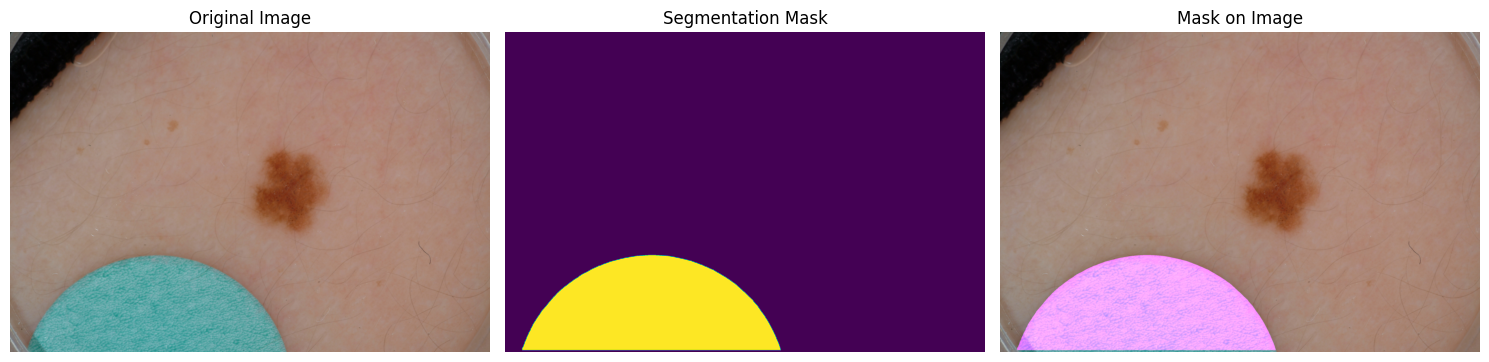

  0%|          | 0/100 [00:21<?, ?it/s]


KeyboardInterrupt: 

In [ ]:
start_time = time.time()
for i, img_dict in enumerate(tqdm(images)):
    mask, bounding_box_on_image = segment_instance_groundingRMBG(img_dict, custom_vocab=custom_vocabulary, 
                                         detection_model=grounding_model, 
                                         processor=processor, 
                                         segmentation_pipe=pipe, 
                                         device=device)
    
    mask2, bounding_box_on_image2 = segment_instance_groundingRMBG2(img_dict, custom_vocab=custom_vocabulary, 
                                         detection_model=grounding_model, 
                                         processor=processor, 
                                         segmentation_model=segmentation_model, 
                                         device=device)
    

    # visualize output
    print(f"Image {i}: {img_dict['file_name']}")
    img = Image.open(img_dict['file_path'])
    mask_on_img = mask_on_image(img, mask)
    mask2_on_img = mask_on_image(img, mask2)
    plot_grid([img, mask, mask_on_img], label=["Original Image", "Segmentation Mask", "Mask on Image"], ncols=3)
    plot_grid([img, mask2, mask2_on_img], label=["Original Image", "Segmentation Mask 2", "Mask 2 on Image"], ncols=3)
    #bounding_box_on_image.show()
    #bounding_box_on_image2.show()
    
end_time = time.time()
print(f"Time taken: {end_time - start_time} seconds")